In [1]:
import numpy as np
import RandomTilings as RT
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from time import perf_counter as time

In [60]:
# Standalone square-orientation rasterizer. Requires numpy and numba.
#
# Call image = aztec_image(M, fac). M is the library's 2*N by 2*N edge matrix.
# Pixels have labels 0=background, 1=north, 2=east, 3=south, 4=west.
# At a shared boundary, the color immediately ABOVE THE PIXEL wins.
# Scale is calibrated to the user's green reference drawing:
# fac=1 has a 6-by-6 tile mask containing 16 pixels.
# Resolution: 2*fac pixels per plotting unit; image side = 4*fac*(N+1).
# Each tile's bounding box has side 6*fac = 3*(2*fac) pixels.
# Stamping uses cached nonzero offsets: no per-pixel mask checks or additions.
# aztec_image(M, fac, parallel=True) runs exactly four parallel tasks,
# one for each relative position within every 2x2 block.
# Set the worker count with numba.set_num_threads(...), outside this module.
# Serial mode remains the default, avoiding parallel overhead on small images.
# The first call includes Numba compilation. Valid tilings are assumed.
# For display: fig, image = plot_aztec(M, fac, filename='aztec.png').
# The display figure is always 4 by 4 inches at 100 DPI (400 by 400 pixels).
# Then call matplotlib.pyplot.show(). Matplotlib is required for display.
import numpy as np
from numba import njit, prange
from functools import lru_cache


def aztec_image(M, fac=1, *, parallel=False):
    # Return an int8 image, row 0 at the top; no plotting objects created.
    M = np.asarray(M)
    if M.ndim != 2 or M.shape[0] != M.shape[1] or M.shape[0] % 2:
        raise ValueError('M must be a square matrix with even side length')
    if M.dtype.kind not in 'biu':
        raise TypeError('M must contain integers or booleans')
    if isinstance(fac, (bool, np.bool_)) or not isinstance(fac, (int, np.integer)) or fac < 1:
        raise ValueError('fac must be a positive integer')
    # Reuse the usual int8 edge matrix without allocating an active-edge copy.
    if M.dtype != np.int8 and M.dtype != np.bool_:
        M = M == 1
    s = 2*int(fac)
    M = np.ascontiguousarray(M)
    offsets = _offsets(s, s*(len(M)+2))
    if parallel:
        # Finish zeroing before any thread stamps. This avoids concurrent
        # initialization/stamping, and all threads share this one array.
        side = s*(len(M)+2)
        image = np.zeros((side,side),dtype=np.int8)
        _fill_parallel(M,s,offsets,image.reshape(-1))
        return image
    return _stamp(M, s, offsets)


@njit(cache=True)
def _masks(s):
    # Two reusable masks, evaluated at pixel centers. s = 2*fac.
    masks = np.zeros((2, 3*s, 3*s), dtype=np.bool_)
    for r in range(3*s):
        for c in range(3*s):
            # Twice local coordinates in output pixels; v increases UP.
            u = 2*c + 1 - 3*s
            v = 3*s - 2*r - 1
            a, b = u+v, u-v
            # Moving upward increases a and decreases b.
            # Thus a's upper bound and b's lower bound are EXCLUDED.
            # A top edge stays background; a bottom edge gets this tile.
            masks[0,r,c] = (-2*s <= a < 2*s) and (-4*s < b <= 4*s)
            masks[1,r,c] = (-4*s <= a < 4*s) and (-2*s < b <= 2*s)
    return masks


@lru_cache(maxsize=8)
def _offsets(s, side):
    # Option 2: compute only the nonzero pixel positions, once per size/scale.
    # Flatten (row, column) into row*side + column to save address arithmetic.
    masks = _masks(s)
    offsets = np.empty((2, 4*s*s), dtype=np.intp)
    for shape in range(2):
        rows, cols = np.nonzero(masks[shape])
        offsets[shape] = rows*side + cols
    offsets.flags.writeable = False
    return offsets


@njit(cache=True)
def _stamp(M, s, offsets):
    L = M.shape[0]
    side = s*(L+2)
    image = np.zeros((side, side), dtype=np.int8)
    flat = image.reshape(side*side)  # View, not a copy.

    for y in range(L):
        for x in range(L):
            if M[y,x] != 1:
                continue
            shape = 0 if (x+y) % 2 else 1
            if x % 2:
                color = 1 if y % 2 == 0 else 2
            else:
                color = 3 if y % 2 else 4
            # Center: row=s*(y+1.5)-.5, col=s*(x+1.5)-.5.
            # The mask's top-left index is (s*y, s*x).
            base = s*y*side + s*x
            for k in range(offsets.shape[1]):
                flat[base + offsets[shape,k]] = color
    return image


@njit(inline='always')
def _put(flat, base, offsets, color):
    for k in range(offsets.size):
        flat[base+offsets[k]] = color


@njit(inline='always')
def _fill_class(M, s, offsets, flat, y0, x0, color):
    # A complete scan of ONE fixed position in all 2x2 blocks.
    # Shape, color and starting parity are fixed before entering these loops.
    L = M.shape[0]
    side = s*(L+2)
    for y in range(y0,L,2):
        row_base = s*y*side
        for x in range(x0,L,2):
            if M[y,x] == 1:
                _put(flat,row_base+s*x,offsets,color)


@njit(cache=True, parallel=True)
def _fill_parallel(M, s, offsets, flat):
    # Exactly four coarse tasks, sharing the same output array.
    # These four decisions happen once per task, never per edge or pixel.
    # Requires a valid tiling: the nonzero stamp pixels must be disjoint.
    for task in prange(4):
        if task == 0:      # Top-left: M[0::2, 0::2], west.
            _fill_class(M,s,offsets[1],flat,0,0,4)
        elif task == 1:    # Top-right: M[0::2, 1::2], north.
            _fill_class(M,s,offsets[0],flat,0,1,1)
        elif task == 2:    # Bottom-left: M[1::2, 0::2], south.
            _fill_class(M,s,offsets[0],flat,1,0,3)
        else:             # Bottom-right: M[1::2, 1::2], east.
            _fill_class(M,s,offsets[1],flat,1,1,2)


def plot_aztec(M, fac=1, *, filename=None, parallel=False):
    # Return (4-by-4-inch figure, full-resolution int8 image).
    # The figure uses a fixed 100 DPI and has no axes margins. Its 400-by-400
    # display resamples the array using nearest-neighbor interpolation.
    # If filename is given, save a PNG at the original array resolution,
    # with DPI metadata for a 4-inch print size. View that PNG at 100% to
    # inspect every original pixel. Screen inches depend on the display,
    # operating-system scaling and notebook/browser zoom.
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap

    image = aztec_image(M, fac, parallel=parallel)
    cmap = ListedColormap(['white', 'red', 'green', 'yellow', '#6666ff'])
    fig = plt.figure(figsize=(4, 4), dpi=100, layout='none')
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(image, origin='upper', interpolation='nearest',
              cmap=cmap, vmin=-0.5, vmax=4.5)
    ax.set_axis_off()
    if filename is not None:
        plt.imsave(filename, image, cmap=cmap, vmin=-0.5, vmax=4.5,
                   origin='upper', format='png', dpi=image.shape[1]/4)
    return fig, image



In [200]:
# Standalone square-orientation rasterizer. Requires numpy and numba.
#
# Call image = aztec_image(M, fac). M is the library's 2*N by 2*N edge matrix.
# Pixels have labels 0=background, 1=north, 2=east, 3=south, 4=west.
# At a shared boundary, the color immediately ABOVE THE PIXEL wins.
# Scale is calibrated to the user's green reference drawing:
# fac=1 has a 6-by-6 tile mask containing 16 pixels.
# Resolution: 2*fac pixels per plotting unit; image side = 4*fac*(N+1).
# Each tile's bounding box has side 6*fac = 3*(2*fac) pixels.
# Stamping uses cached nonzero offsets: no per-pixel mask checks or additions.
# aztec_image(M, fac, parallel=True) enables parallel rows of 2x2 blocks.
# Set the worker count with numba.set_num_threads(...), outside this module.
# Serial mode remains the default, avoiding parallel overhead on small images.
# The first call includes Numba compilation. Valid tilings are assumed.
# For display: fig, image = plot_aztec(M, fac, filename='aztec.png').
# The display figure is always 4 by 4 inches at 100 DPI (400 by 400 pixels).
# Then call matplotlib.pyplot.show(). Matplotlib is required for display.
import numpy as np
from numba import njit, prange
from functools import lru_cache


def aztec_image(M, fac=1, *, parallel=False):
    # Return an int8 image, row 0 at the top; no plotting objects created.
    M = np.asarray(M)
    if M.ndim != 2 or M.shape[0] != M.shape[1] or M.shape[0] % 2:
        raise ValueError('M must be a square matrix with even side length')
    if M.dtype.kind not in 'biu':
        raise TypeError('M must contain integers or booleans')
    if isinstance(fac, (bool, np.bool_)) or not isinstance(fac, (int, np.integer)) or fac < 1:
        raise ValueError('fac must be a positive integer')
    # Reuse the usual int8 edge matrix without allocating an active-edge copy.
    if M.dtype != np.int8 and M.dtype != np.bool_:
        M = M == 1
    s = 2*int(fac)
    M = np.ascontiguousarray(M)
    offsets = _offsets(s, s*(len(M)+2))
    if parallel:
        # Finish zeroing before any thread stamps. This avoids concurrent
        # initialization/stamping, and all threads share this one array.
        side = s*(len(M)+2)
        image = np.zeros((side,side),dtype=np.int8)
        _fill_parallel(M,s,offsets,image.reshape(-1))
        return image
    return _stamp(M, s, offsets)


@njit(cache=True)
def _masks(s):
    # Two reusable masks, evaluated at pixel centers. s = 2*fac.
    masks = np.zeros((2, 3*s, 3*s), dtype=np.bool_)
    for r in range(3*s):
        for c in range(3*s):
            # Twice local coordinates in output pixels; v increases UP.
            u = 2*c + 1 - 3*s
            v = 3*s - 2*r - 1
            a, b = u+v, u-v
            # Moving upward increases a and decreases b.
            # Thus a's upper bound and b's lower bound are EXCLUDED.
            # A top edge stays background; a bottom edge gets this tile.
            masks[0,r,c] = (-2*s <= a < 2*s) and (-4*s < b <= 4*s)
            masks[1,r,c] = (-4*s <= a < 4*s) and (-2*s < b <= 2*s)
    return masks


@lru_cache(maxsize=8)
def _offsets(s, side):
    # Option 2: compute only the nonzero pixel positions, once per size/scale.
    # Flatten (row, column) into row*side + column to save address arithmetic.
    masks = _masks(s)
    offsets = np.empty((2, 4*s*s), dtype=np.intp)
    for shape in range(2):
        rows, cols = np.nonzero(masks[shape])
        offsets[shape] = rows*side + cols
    offsets.flags.writeable = False
    return offsets


@njit(cache=True)
def _stamp(M, s, offsets):
    L = M.shape[0]
    side = s*(L+2)
    image = np.zeros((side, side), dtype=np.int8)
    flat = image.reshape(side*side)  # View, not a copy.

    for y in range(L):
        for x in range(L):
            if M[y,x] != 1:
                continue
            shape = 0 if (x+y) % 2 else 1
            if x % 2:
                color = 1 if y % 2 == 0 else 2
            else:
                color = 3 if y % 2 else 4
            # Center: row=s*(y+1.5)-.5, col=s*(x+1.5)-.5.
            # The mask's top-left index is (s*y, s*x).
            base = s*y*side + s*x
            for k in range(offsets.shape[1]):
                flat[base + offsets[shape,k]] = color
    return image


@njit(inline='always')
def _put(flat, base, offsets, color):
    for k in range(offsets.size):
        flat[base+offsets[k]] = color


@njit(cache=True, parallel=True)
def _fill_parallel(M, s, offsets, flat):
    # Each task handles one row of 2x2 blocks. Numba batches those tasks
    # among its threads. Only this OUTER loop uses prange.
    # Requires a valid tiling: nonzero stamp pixels must be disjoint.
    L = M.shape[0]
    side = s*(L+2)
    down = s*side
    for block_row in prange(L//2):
        y = 2*np.int64(block_row)
        for x in range(0,L,2):
            base = s*y*side+s*x
            # Top-left, top-right, bottom-left, bottom-right:
            # shape/color are constants; only edge activity is tested.
            if M[y,x] == 1:
                _put(flat,base,offsets[1],4)
            if M[y,x+1] == 1:
                _put(flat,base+s,offsets[0],1)
            if M[y+1,x] == 1:
                _put(flat,base+down,offsets[0],3)
            if M[y+1,x+1] == 1:
                _put(flat,base+down+s,offsets[1],2)


def plot_aztec(M, fac=1, cmap = None, filename=None, parallel=False):
    # Return (4-by-4-inch figure, full-resolution int8 image).
    # The figure uses a fixed 100 DPI and has no axes margins. Its 400-by-400
    # display resamples the array using nearest-neighbor interpolation.
    # If filename is given, save a PNG at the original array resolution,
    # with DPI metadata for a 4-inch print size. View that PNG at 100% to
    # inspect every original pixel. Screen inches depend on the display,
    # operating-system scaling and notebook/browser zoom.
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap

    image = aztec_image(M, fac, parallel=parallel)
    if cmap == None:
        cmap = ['white', 'red', 'green', 'yellow', '#6666ff']
    cmap = ListedColormap(cmap)
    fig = plt.figure(figsize=(4, 4), dpi=100, layout='none')
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(image, origin='upper', interpolation='nearest',
              cmap=cmap, vmin=-0.5, vmax=4.5)
    ax.set_axis_off()
    if filename is not None:
        plt.imsave(filename, image, cmap=cmap, vmin=-0.5, vmax=4.5,
                   origin='upper', format='png', dpi=image.shape[1]/4)
    return fig, image


In [118]:
n = 4000
A = RT.Aztec(n)
A.shuffle()

3.268705800001044


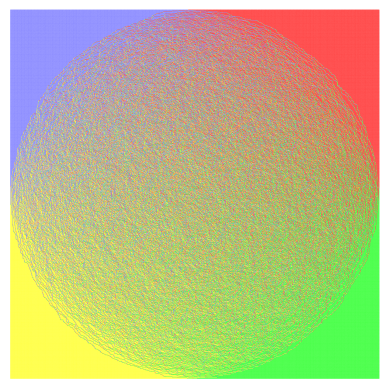

In [51]:
t1 = time()
A.plot(orientation = 'square')
print(time()-t1)
fig = A.fig

0.103895400010515


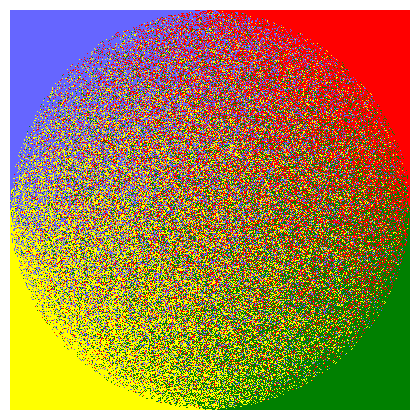

In [116]:
fac = 1
M = A.get_edge_matrix()


t1 = time()
fig, image = plot_aztec(M, fac,parallel=1)
print(time()-t1)

In [109]:
4004**2

16032016

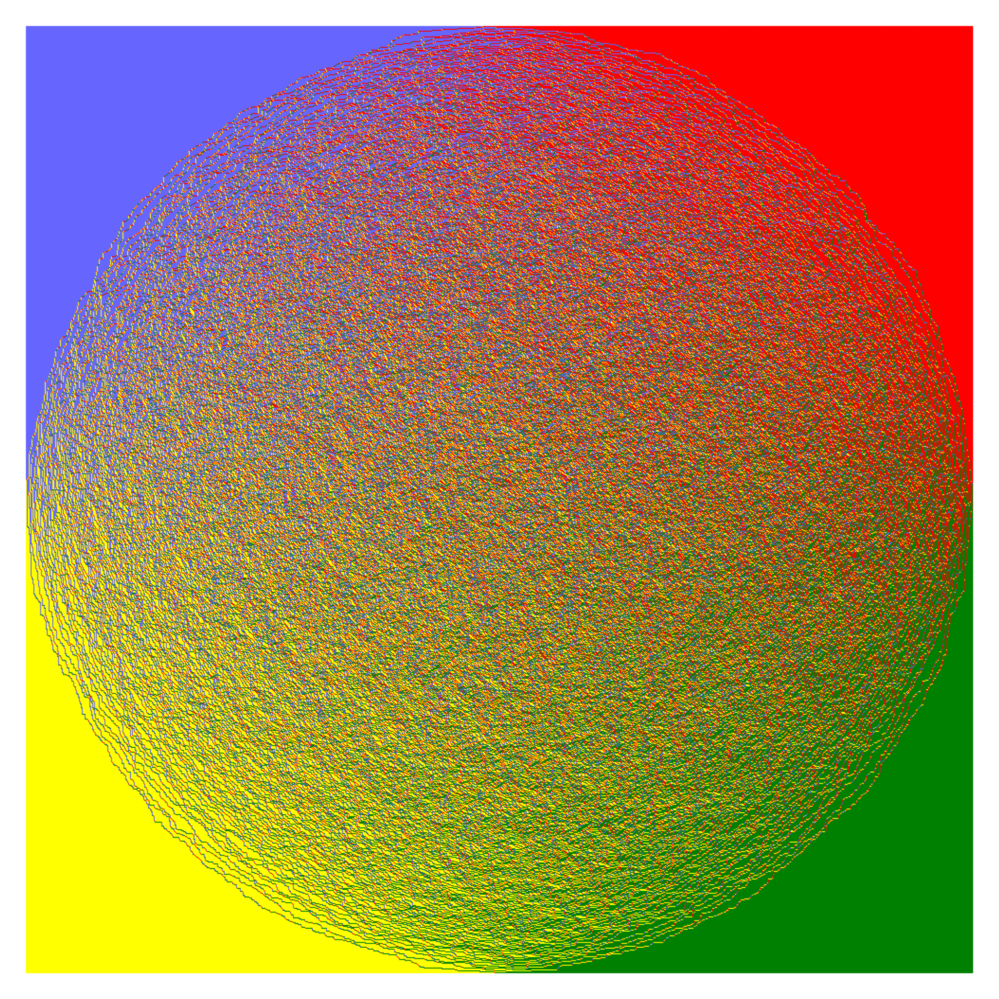

In [ ]:
plt.figure(dpi=800)
cmap = ListedColormap(['white', 'red', 'green', 'yellow', '#6666ff'])
plt.imshow(image, origin='upper', interpolation=None,
              cmap=cmap, vmin=-0.5, vmax=4.5)
plt.axis('off')
plt.show()

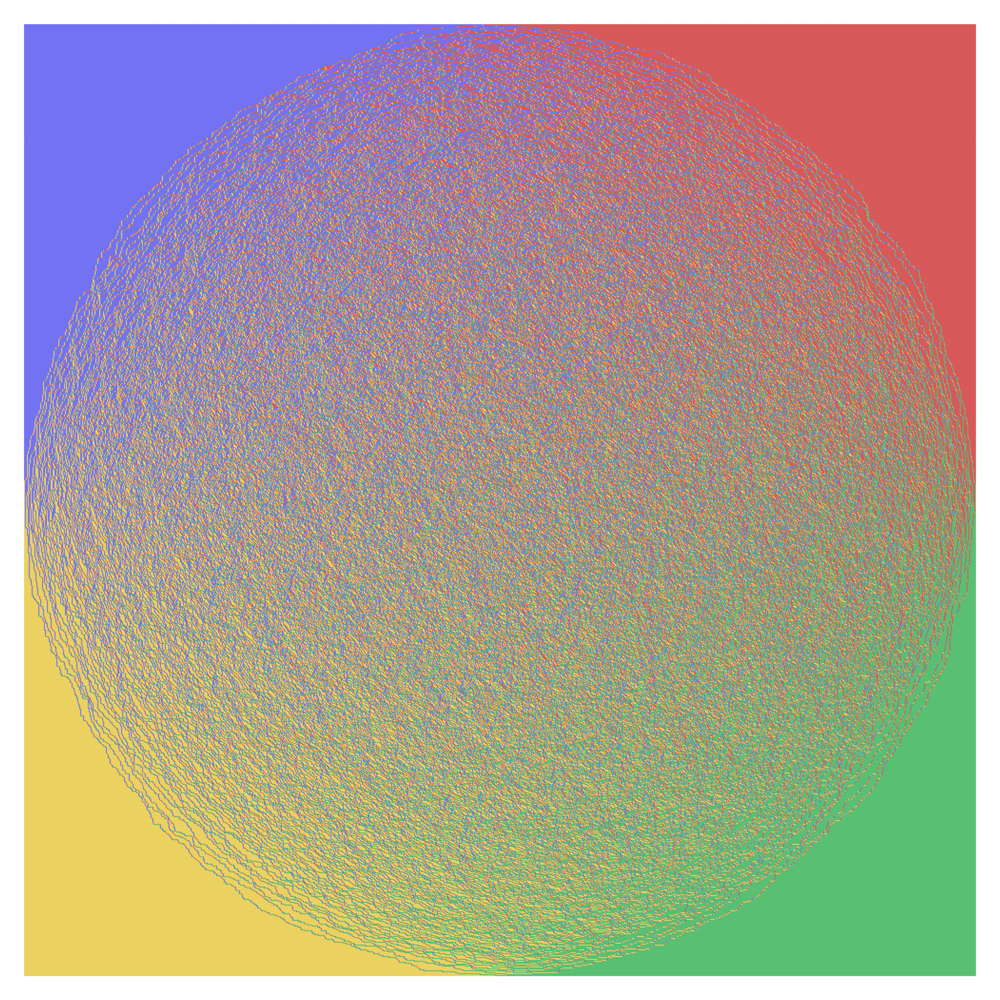

In [92]:
fig.set_dpi(1000)
fig

In [25]:
image.shape

(12, 12)

In [19]:
fig.savefig('test1.png',dpi=500)

In [109]:
M = A.get_edge_matrix()

In [102]:
def comp_center(fac,x,y):
    if fac%2==0:
        x0 = 3*fac//2
        y0 = 3*fac//2
        x  = x0 +(fac-1)*((x+y)%2)+(x-x%2)*fac+(y%2)*fac-fac*(y%2)
        y  = y0 + fac*y

    return x,y

comp_center(2,0,1)

(4, 5)

In [42]:
def pplot(M,fac):
    N = M.shape[0]//2
    A = np.zeros((3*fac*N,3*fac*N))

    cmap = np.array([[1.0,1.0,1.0],
                     [1.0,0.0,0.0],
                     [0.0,1.0,0.0],
                     [1.0,1.0,0.0],
                     [0.4,0.4,1.0]])

    plt.imshow(A, cmap=ListedColormap(cmap), vmin=0, vmax=4)

In [120]:
from PIL import Image

colors = np.array([
    [1.00, 1.00, 1.00],
    [0.85, 0.35, 0.35],
    [0.35, 0.75, 0.45],
    [0.92, 0.82, 0.38],
    [0.45, 0.45, 0.95],
])

img = Image.fromarray(image.astype(np.uint8), mode="P")
img.putpalette((colors * 255).astype(np.uint8).flatten().tolist())
img.save("tiling.png", optimize=True)

In [121]:
image.shape

(8004, 8004)

In [128]:
RT.config.log_variant=1

In [ ]:
a = 1j
b = 1
c = 1j
w = np.array([[b,a,a,b,c],
              [b,a,a,b,c],
              [a,b,a,b,c],
              [b,a,a,b,c]])

In [234]:
cmap = [[1,1,1],
        [0,0,0],
        [1,0,0],
        [0,0,0],
        [1,0,0]]

cmap = np.array([[255,255,255],
    [139,  18, 32],  # Blood red
    [196,  69, 16],  # Burnt orange
    [ 65,  30, 78],  # Deep violet
    [204, 157, 28],  # Dark gold
]) / 255.0
cmap = cmap.tolist()
cmap = None

In [371]:
1*(np.random.random((4,4))>.5)

array([[1, 0, 1, 0],
       [1, 1, 1, 1],
       [1, 1, 1, 0],
       [1, 1, 1, 1]])

In [377]:
w

array([[1, 1, 1],
       [1, 1, 1],
       [0, 1, 0],
       [1, 0, 0],
       [1, 0, 1]])

In [406]:
n = 1000
a = 0
b = 1
c = 0
w = np.array([[b,a,a,b,c],
              [b,a,b,a,c],
              [a,b,a,b,c],
              [b,a,a,b,c]])

w = np.array([[0,0,1,1],
              [1,0,0,1],
              [0,1,0,0],
              [0,0,1,0]])

k = 5
w = 1*(np.random.random((k,k))>.85)
w = w+w.T
w += w[::-1,::-1]
print(w)

w = np.array([[1,0,0,0,0,0,0],
              [0,0,1,0,0,1,0],
              [0,0,0,0,0,0,0],
              [0,0,0,1,0,0,0],
              [1,0,0,0,0,1,0],
              [0,1,0,0,0,0,0],
              [0,0,1,0,0,0,1],])

%matplotlib qt
A = RT.Aztec(n,w)
A.shuffle()
M = A.get_edge_matrix()
_=plot_aztec(M,cmap = cmap,filename='spider plot.png')

[[0 2 0 0 0]
 [2 0 0 2 0]
 [0 0 0 0 0]
 [0 2 0 0 2]
 [0 0 0 2 0]]


In [384]:
import numpy as np
from operator import index

def windmill_weights(n):
    n = 2*n
    n = index(n)
    if n < 2 or n % 2:
        raise ValueError("n must be a positive even integer")

    w = np.zeros((n, n), dtype=int)
    m = n // 2
    k = np.arange(m)

    w[m - 1 - k, m - 1 + k] = 1  # Upper arm
    w[m - 1 + k, m + k] = 1      # Right arm
    w[m + k, m - k] = 1          # Lower arm
    w[m - k, m - 1 - k] = 1      # Left arm

    return w

w = windmill_weights(6)

In [411]:
2* 20/250

0.16